# Experiment 2: States versus Symbols at Fixed $C$

This notebook reproduces **Experiment 2** from the results report.

### Protocol
- **Objective**: Investigate whether AC capacity depends solely on total transitions $C$ or on how transitions are factorised between internal states and input alphabet: $C = |Q||\Sigma|$.
- **Fixed Transition Counts**: $C \in \{80, 120, 160\}$.
- **Alphabet Sizes**: $|\Sigma| \in \{2, 4, 8, 10, 20, 40\}$, with $|Q| = C/|\Sigma|$.
- **Evaluations**:
  1. Continuous unseen path survival up to $L=640$.
  2. Margin to nearest competing state: $(\text{score}_{\text{target}} - \max \text{score}_{\text{competitors}})/K$.


In [1]:
from __future__ import annotations

import gc
import hashlib
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().resolve()
if not (ROOT / 'README.md').is_file():
    ROOT = ROOT.parent
PYAC_SRC = (ROOT.parent / 'pyac' / 'src').resolve()
if not PYAC_SRC.is_dir():
    raise RuntimeError(f'PYAC source not found at {PYAC_SRC}')
sys.path.insert(0, str(PYAC_SRC))

from pyac import Area, Assembly, Connection, Hebbian, Homeostasis, Network, NetworkSpec, decode, overlap, overlap_vector

N, K, P, BETA = 5000, 30, 0.4, 0.1
PRESENTATIONS = 15
FACTORISATION_TRANSITION_COUNTS = (80, 120, 160)
ALPHABET_SIZES = (2, 4, 8, 10, 20, 40)
LENGTHS = (10, 20, 40, 80, 160, 320, 640)
DFA_REPLICATES = 5
STRINGS_PER_DFA = 10

plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
print(f'Experiment 2 setup ready: N={N}, K={K}, p={P}, beta={BETA}')


Experiment 2 setup ready: N=5000, K=30, p=0.4, beta=0.1


In [2]:
def disjoint_caps(area: str, count: int, seed: int) -> dict[int, Assembly]:
    if count * K > N:
        raise ValueError(f'{count} caps of size {K} do not fit in {area!r}')
    neurons = np.random.default_rng(seed).permutation(N)[:count * K]
    return {label: Assembly(area, neurons[label * K:(label + 1) * K]) for label in range(count)}

def balanced_random_dfa(states_n: int, alphabet_n: int, seed: int) -> np.ndarray:
    destinations = np.resize(np.arange(states_n, dtype=np.int64), states_n * alphabet_n)
    np.random.default_rng(seed).shuffle(destinations)
    return destinations.reshape(states_n, alphabet_n)

def representations(states_n: int, alphabet_n: int, transitions_n: int, seed: int):
    symbols = disjoint_caps('symbol', alphabet_n, seed)
    states = disjoint_caps('state', states_n, seed + 1)
    flat = disjoint_caps('transition', transitions_n, seed + 2)
    order = np.random.default_rng(seed + 3).permutation(transitions_n)
    transitions = {
        (state, symbol): flat[int(order[state * alphabet_n + symbol])]
        for state in range(states_n) for symbol in range(alphabet_n)
    }
    return symbols, states, transitions

def build_network(seed: int) -> Network:
    spec = NetworkSpec(
        areas=(Area('symbol', N, K, kind='input'), Area('state', N, K), Area('transition', N, K)),
        connections=(
            Connection('symbol', 'transition', p=P),
            Connection('state', 'transition', p=P),
            Connection('transition', 'state', p=P),
        ),
        plasticity=Hebbian(BETA),
        homeostasis=Homeostasis(mode='none', on_init=False),
    )
    return Network(spec, seed=seed)

def train(network: Network, delta: np.ndarray, symbols: dict[int, Assembly], states: dict[int, Assembly], transitions: dict[tuple[int, int], Assembly], seed: int) -> None:
    rng = np.random.default_rng(seed)
    contexts = list(transitions)
    for _ in range(PRESENTATIONS):
        rng.shuffle(contexts)
        for state, symbol in contexts:
            network.clear_activity()
            network.set_activity('state', states[state])
            network.step(clamps={'symbol': symbols[symbol]}, forced_activations={'transition': transitions[(state, symbol)]}, targets=('transition',), plasticity=True)
            network.step(forced_activations={'state': states[int(delta[state, symbol])]}, targets=('state',), plasticity=True)

def evaluate_one_step(network: Network, delta: np.ndarray, symbols: dict[int, Assembly], states: dict[int, Assembly], transitions: dict[tuple[int, int], Assembly]) -> dict[str, float]:
    transition_items = tuple(transitions.items())
    transition_labels = [item[0] for item in transition_items]
    transition_refs = [item[1] for item in transition_items]
    state_labels = tuple(states.keys())
    state_refs = tuple(states.values())
    arc_margins = []
    for state in state_labels:
        for symbol in symbols:
            network.clear_activity()
            network.set_activity('state', states[state])
            network.step(clamps={'symbol': symbols[symbol]}, targets=('transition',), plasticity=False)
            arc_active = network.assembly('transition')
            scores = overlap_vector(arc_active, transition_refs)
            target_index = transition_labels.index((state, symbol))
            competitor_mask = np.ones(len(scores), dtype=bool)
            competitor_mask[target_index] = False
            competitor_max = scores[competitor_mask].max() if competitor_mask.any() else 0
            arc_margins.append(float(scores[target_index] - competitor_max) / K)
    return dict(arc_margin=float(np.mean(arc_margins)))

def evaluate_strings(network: Network, delta: np.ndarray, symbols: dict[int, Assembly], states: dict[int, Assembly], seed: int) -> list[dict[str, float | int]]:
    rng = np.random.default_rng(seed)
    alphabet_n = len(symbols)
    state_count = len(states)
    rows = []
    for sample in range(STRINGS_PER_DFA):
        start_state = int(rng.integers(state_count))
        symbol_sequence = [int(symbol) for symbol in rng.integers(alphabet_n, size=max(LENGTHS))]
        network.clear_activity()
        network.set_activity('state', states[start_state])
        current_ground_state = start_state
        matches = []
        for symbol in symbol_sequence:
            current_ground_state = int(delta[current_ground_state, symbol])
            network.step(clamps={'symbol': symbols[symbol]}, targets=('transition',), plasticity=False)
            network.step(targets=('state',), plasticity=False)
            active_state = network.assembly('state')
            decoded_state = decode(active_state, states)
            matches.append(decoded_state == current_ground_state)
        for length in LENGTHS:
            prefix_matches = np.asarray(matches[:length], dtype=bool)
            rows.append(dict(
                sample=sample,
                length=length,
                complete_path_survival=float(prefix_matches.all()),
            ))
    return rows

def run_condition(transitions_n: int, alphabet_n: int, replicate: int):
    states_n = transitions_n // alphabet_n
    paired_seed = 50_000 + 1_000 * transitions_n + replicate
    delta = balanced_random_dfa(states_n, alphabet_n, paired_seed + 100_000 * alphabet_n)
    network = build_network(paired_seed + 1_000_000)
    symbols, states, transitions = representations(states_n, alphabet_n, transitions_n, paired_seed + 2_000_000)
    train(network, delta, symbols, states, transitions, paired_seed + 3_000_000 + alphabet_n)
    metrics = evaluate_one_step(network, delta, symbols, states, transitions)
    strings = evaluate_strings(network, delta, symbols, states, paired_seed + 4_000_000 + alphabet_n)
    del network
    gc.collect()
    return dict(transitions=transitions_n, alphabet=alphabet_n, states=states_n, replicate=replicate, **metrics, strings=strings)


In [3]:
# Check for precomputed factorisation data to allow instantaneous plotting
DATA_CACHE = ROOT / 'data' / 'fsm_factorisation_precomputed.json'
RUN_FULL_SIMULATION = False  # Set to True to re-execute all 90 simulation runs (approx 12-14 mins)

if DATA_CACHE.is_file() and not RUN_FULL_SIMULATION:
    print(f'Loading precomputed 5-replicate factorisation data from {DATA_CACHE} ...')
    with open(DATA_CACHE) as f:
        cache = json.load(f)
    one_step_summary = cache['one_step_summary']
    path_survival = {int(k): np.array(v) for k, v in cache['path_survival'].items()}
else:
    print('Running full factorisation simulation across all conditions...')
    results = []
    for c in FACTORISATION_TRANSITION_COUNTS:
        for a in ALPHABET_SIZES:
            print(f'Running C={c}, |Sigma|={a}, |Q|={c//a} ...')
            for rep in range(DFA_REPLICATES):
                results.append(run_condition(c, a, rep))
    
    one_step_summary = []
    for c in FACTORISATION_TRANSITION_COUNTS:
        for a in ALPHABET_SIZES:
            group = [r for r in results if r['transitions'] == c and r['alphabet'] == a]
            one_step_summary.append(dict(
                transitions=c, alphabet=a, states=c//a,
                arc_margin=float(np.mean([r['arc_margin'] for r in group])),
            ))
    
    path_survival = {}
    for c in FACTORISATION_TRANSITION_COUNTS:
        path = np.empty((len(LENGTHS), len(ALPHABET_SIZES)), dtype=float)
        for column, a in enumerate(ALPHABET_SIZES):
            string_rows = [item for r in results if r['transitions'] == c and r['alphabet'] == a for item in r['strings']]
            for row_idx, length in enumerate(LENGTHS):
                group = [row for row in string_rows if row['length'] == length]
                path[row_idx, column] = np.mean([row['complete_path_survival'] for row in group])
        path_survival[c] = path

    # Cache results
    DATA_CACHE.parent.mkdir(parents=True, exist_ok=True)
    with open(DATA_CACHE, 'w') as f:
        json.dump({
            'one_step_summary': one_step_summary,
            'path_survival': {k: v.tolist() for k, v in path_survival.items()}
        }, f, indent=2)
    print(f'Saved cache to {DATA_CACHE}')

print('Data ready for plotting.')


Loading precomputed 5-replicate factorisation data from /home/johnh/Documents/ac-fsm-learning/data/fsm_factorisation_precomputed.json ...
Data ready for plotting.


<>:34: SyntaxWarning: "\S" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\S"? A raw string is also an option.
<>:34: SyntaxWarning: "\S" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\S"? A raw string is also an option.
/tmp/ipykernel_3598295/3253355257.py:34: SyntaxWarning: "\S" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\S"? A raw string is also an option.
  axes[1].set_xlabel('Alphabet Size $|\Sigma|$ (with $|Q|$ at $C=160$ below)')


Saved figure to /home/johnh/Documents/ac-fsm-learning/figures/factorisation_frontier_2panel.png
Synced figure to /home/johnh/Documents/Notes/University/Elec/Paper/Results/assets/factorisation_frontier_2panel.png


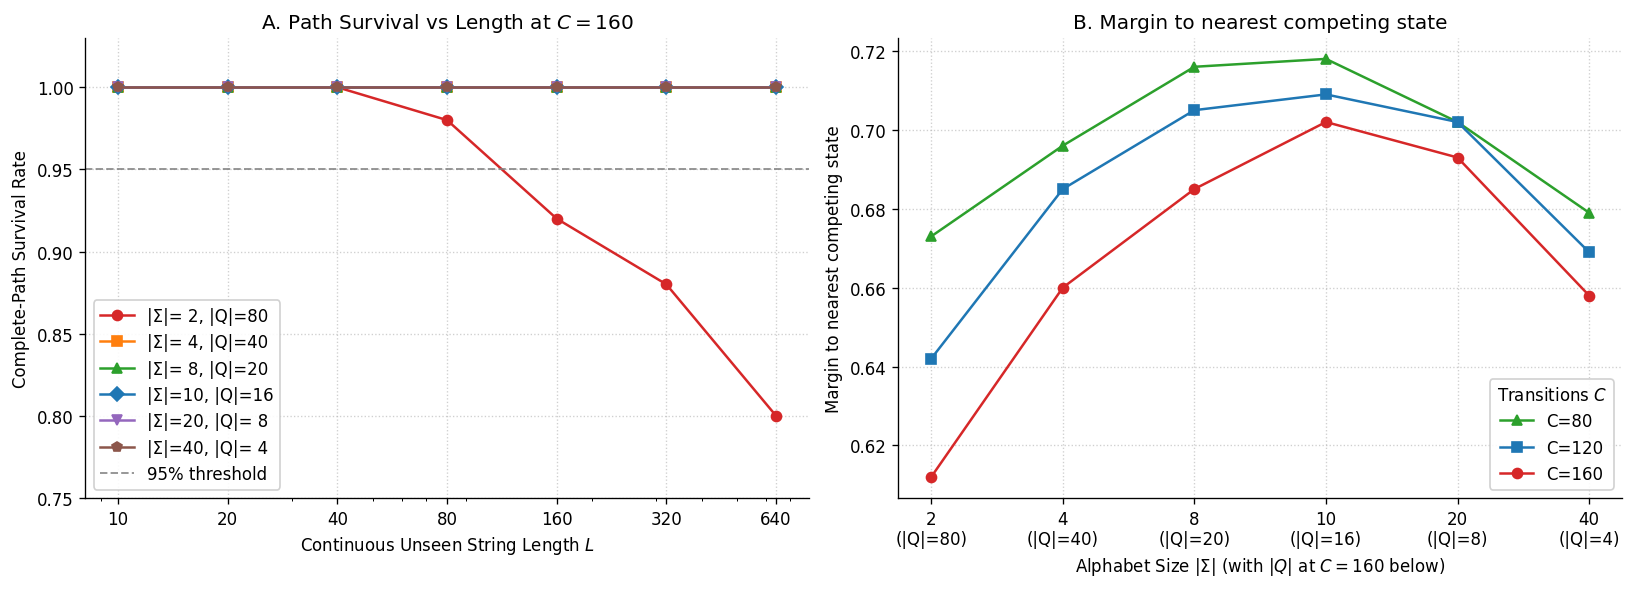

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), constrained_layout=True)

# Panel A: Path Survival vs Length at C=160
colors = {2: '#d62728', 4: '#ff7f0e', 8: '#2ca02c', 10: '#1f77b4', 20: '#9467bd', 40: '#8c564b'}
markers = {2: 'o', 4: 's', 8: '^', 10: 'D', 20: 'v', 40: 'p'}
for s in ALPHABET_SIZES:
    q = 160 // s
    surv_vals = [path_survival[160][row_idx, ALPHABET_SIZES.index(s)] for row_idx in range(len(LENGTHS))]
    axes[0].plot(LENGTHS, surv_vals, marker=markers[s], color=colors[s], label=f'|Σ|={s:2d}, |Q|={q:2d}')

axes[0].axhline(0.95, color='gray', linestyle='--', linewidth=1.2, alpha=0.8, label='95% threshold')
axes[0].set_xscale('log')
axes[0].set_xticks(LENGTHS)
axes[0].set_xticklabels([str(l) for l in LENGTHS])
axes[0].set_ylim(0.75, 1.03)
axes[0].set_xlabel('Continuous Unseen String Length $L$')
axes[0].set_ylabel('Complete-Path Survival Rate')
axes[0].set_title('A. Path Survival vs Length at $C=160$')
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend(loc='lower left', frameon=True, framealpha=0.9)

# Panel B: Representational Stability vs Factorisation
c_colors = {80: '#2ca02c', 120: '#1f77b4', 160: '#d62728'}
c_markers = {80: '^', 120: 's', 160: 'o'}
x_indices = np.arange(len(ALPHABET_SIZES))
for c in FACTORISATION_TRANSITION_COUNTS:
    c_rows = [r for r in one_step_summary if r['transitions'] == c]
    c_rows.sort(key=lambda x: x['alphabet'])
    margins = [r['arc_margin'] for r in c_rows]
    axes[1].plot(x_indices, margins, marker=c_markers[c], color=c_colors[c], label=f'C={c}')

axes[1].set_xticks(x_indices)
axes[1].set_xticklabels([f'{s}\n(|Q|={160//s})' for s in ALPHABET_SIZES])
axes[1].set_xlabel('Alphabet Size $|\Sigma|$ (with $|Q|$ at $C=160$ below)')
axes[1].set_ylabel('Margin to nearest competing state')
axes[1].set_title('B. Margin to nearest competing state')
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].legend(title='Transitions $C$', loc='lower right', frameon=True, framealpha=0.9)

out_fig = ROOT / 'figures' / 'factorisation_frontier_2panel.png'
fig.savefig(out_fig, dpi=200, bbox_inches='tight')
print(f'Saved figure to {out_fig}')

# Sync to Obsidian vault
obsidian_asset = Path('/home/johnh/Documents/Notes/University/Elec/Paper/Results/assets/factorisation_frontier_2panel.png')
import shutil
shutil.copy(out_fig, obsidian_asset)
print(f'Synced figure to {obsidian_asset}')

plt.show()


### Key Findings
1. **This suggests that total transition count alone does not determine capacity; the state–alphabet factorisation also matters.**
2. **State–Alphabet Asymmetry at Fixed Transition Count ($C=160$)**:
   - The binary condition ($|\Sigma|=2, |Q|=80$) degrades steadily to 80.0% survival at $L=640$.
   - In stark contrast, every factorisation with $|\Sigma| \ge 4$ ($|Q| \le 40$) achieves **100.0% complete-path survival** through $L=640$.
3. **Margin to nearest competing state**:
   - The margin follows an inverted-U curve across alphabet size, peaking at balanced factorisations ($|\Sigma| \approx 10, |Q| \approx 16$) at $\sim 0.70$–$0.72$.
   - Margin drops significantly when $|Q|$ is pushed to 80 (falling to $0.612$ at $C=160$).
